# ETF Cluster Evaluation — accuracy per experiment

Evaluates a `train_cluster.py` checkpoint on real multi-tag cluster data. Each
**experiment** (one physical deployment / room scan) is reported on its own.

1. Loads the checkpoint + its `_config.json`, and the dataset it was trained on.
2. Rebuilds the **exact** train/val partition from `<run_stem>_split.csv` and
   applies the scalers stored in the checkpoint.
3. Runs inference and reports overall and per-experiment metrics, seen vs unseen
   experiments, and the train↔val gap.

> With the default random split every experiment (and often every sub-cluster) is
> on both sides, so the numbers are in-distribution. Train with
> `--val_experiments` for a genuine "new room" test.

In [1]:
import glob
import importlib
import json
import os
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Locate multitag_ml_training/ so the CWD doesn't matter
HERE = os.path.abspath(".")
while HERE != "/" and not os.path.isfile(os.path.join(HERE, "train_cluster.py")):
    if os.path.isfile(os.path.join(HERE, "multitag_ml_training", "train_cluster.py")):
        HERE = os.path.join(HERE, "multitag_ml_training")
        break
    HERE = os.path.dirname(HERE)
assert os.path.isfile(os.path.join(HERE, "train_cluster.py")), \
    "Could not locate multitag_ml_training/train_cluster.py — launch from inside RFImaging/"
if HERE not in sys.path:
    sys.path.insert(0, HERE)

import train_cluster as _tc
importlib.reload(_tc)
from train_cluster import (SUB_KEYS, load_for_args, load_split, preprocess,
                           scalers_from_checkpoint, split_indices)
from MLScripts.models.transformer import TagPairTransformer   # path set up by train_cluster

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("ml dir  :", HERE)
print("T2T_ROOT:", _tc.T2T_ROOT)

ml dir  : /home/manaj/RFImaging/multitag_ml_training
T2T_ROOT: /home/manaj/T2TSionnaSim


## Configuration

`CHECKPOINT_PATH = None` picks the newest checkpoint in `SAVED_DIR`. The dataset
comes from the checkpoint's `_config.json` unless `DATASET_PATH` overrides it.
`EVAL_EXPERIMENTS` selects which val experiments every table and chart reports on.

In [2]:
CHECKPOINT_PATH = "/home/manaj/RFImaging/multitag_ml_training/Saved/ETF_realistic_45slots_attn_d128_l6_ep300_s42_1014155745_ft_frz5_valexp12_ep20_s42_1014221153.pth"      # None → newest ETF_cluster_*.pth in SAVED_DIR
DATASET_PATH    = None      # None → the CSV the checkpoint was trained on
SAVED_DIR       = os.path.join(HERE, "Saved")

EVAL_EXPERIMENTS       = None   # val experiments to report on; None → all
EVAL_TRAIN_EXPERIMENTS = None   # train-side reference; None → all
EVAL_TRAIN_SPLIT       = True   # also score the train split (overfit gap)
VIZ_EXPERIMENTS        = None   # experiments for the wall-geometry plots; None → all of EVAL_EXPERIMENTS
VIZ_LIMIT              = 400    # val samples drawn per experiment in those plots

if CHECKPOINT_PATH is None:
    _cands = sorted((p for p in glob.glob(os.path.join(SAVED_DIR, "ETF_cluster_*.pth"))
                     if os.path.exists(p.replace(".pth", "_config.json"))),
                    key=os.path.getmtime)
    if not _cands:
        raise FileNotFoundError(
            f"No checkpoint in {SAVED_DIR}. Train one with\n"
            f"  python multitag_ml_training/train_cluster.py --dataset multitag/cluster_features_K10_P1.csv")
    for _p in _cands[-5:]:
        print(f"  {'->' if _p == _cands[-1] else '  '} {os.path.basename(_p)}")
    CHECKPOINT_PATH = _cands[-1]

config_path = CHECKPOINT_PATH.replace(".pth", "_config.json")
with open(config_path) as f:
    run_cfg = json.load(f)

train_args = dict(run_cfg["args"])
if DATASET_PATH is not None and os.path.realpath(DATASET_PATH) != os.path.realpath(train_args["dataset"]):
    print(f"[warn] evaluating on {DATASET_PATH}, but the checkpoint was trained on "
          f"{train_args['dataset']} — the split below is NOT the training split.")
    train_args["dataset"] = DATASET_PATH
DATASET_PATH = train_args["dataset"]
assert os.path.exists(DATASET_PATH), f"Dataset not found: {DATASET_PATH}"

print(f"\nCheckpoint: {CHECKPOINT_PATH}")
print(f"Dataset   : {DATASET_PATH}")
print(json.dumps({k: v for k, v in run_cfg.items()
                  if k not in ("train_losses", "val_losses", "args")}, indent=1))


Checkpoint: /home/manaj/RFImaging/multitag_ml_training/Saved/ETF_realistic_45slots_attn_d128_l6_ep300_s42_1014155745_ft_frz5_valexp12_ep20_s42_1014221153.pth
Dataset   : /home/manaj/RFImaging/multitag/cluster_features_K10_P1.csv
{
 "run_stem": "ETF_realistic_45slots_attn_d128_l6_ep300_s42_1014155745_ft_frz5_valexp12_ep20_s42_1014221153",
 "model_config": {
  "n_slots": 45,
  "feat_dim": 50,
  "d_model": 128,
  "nhead": 4,
  "num_layers": 6,
  "dim_feedforward": 512,
  "dropout": 0.1,
  "out_dists": 4,
  "out_angles": 4
 },
 "feature_slices": {
  "theta": [
   0,
   22
  ],
  "alpha": [
   22,
   44
  ],
  "pos": [
   44,
   50
  ]
 },
 "split_file": "ETF_realistic_45slots_attn_d128_l6_ep300_s42_1014155745_ft_frz5_valexp12_ep20_s42_1014221153_split.csv",
 "n_freq": 22,
 "n_train": 28761,
 "n_val": 9009,
 "finetuned_from": "/home/manaj/T2TSionnaSim/MLScripts/Saved/ETF_realistic_45slots_attn_d128_l6_ep300_s42_1014155745.pth",
 "fixed_scalers": true,
 "pretrained_metrics": {
  "mae_dist_c

## Load model

Device     : cuda
Parameters : 1,203,464
Best epoch : 5 / 20


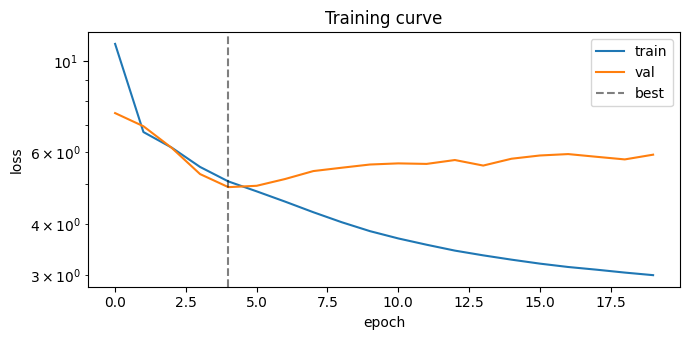

In [3]:
device = torch.device(
    "mps"  if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available()         else
    "cpu"
)
ckpt  = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
model = TagPairTransformer(**run_cfg["model_config"])
model.load_state_dict(ckpt["model_state_dict"])
model.to(device).eval()

print(f"Device     : {device}")
print(f"Parameters : {sum(p.numel() for p in model.parameters()):,}")
print(f"Best epoch : {run_cfg['best_epoch']} / {train_args['epochs']}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(run_cfg["train_losses"], label="train")
ax.plot(run_cfg["val_losses"], label="val")
ax.axvline(run_cfg["best_epoch"] - 1, color="k", ls="--", alpha=0.5, label="best")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("Training curve"); ax.legend(); plt.tight_layout(); plt.show()

## Load data and the saved partition

Same loader and feature flags as `train_cluster.main()`. The partition comes from
`<run_stem>_split.csv` (samples matched by experiment / combination / permutation /
run); the scalers are the ones stored in the checkpoint, not refit.

In [4]:
%%time
(X_raw, Y_dists, Y_angles, centroids, poses,
 n_pairs, n_freq, meta_df, feature_slices) = load_for_args(train_args)
assert X_raw.shape[2] == run_cfg["model_config"]["feat_dim"], (
    f"feat_dim mismatch: model expects {run_cfg['model_config']['feat_dim']}, "
    f"data has {X_raw.shape[2]} — different feature flags or K.")

SPLIT_PATH = os.path.join(os.path.dirname(CHECKPOINT_PATH), run_cfg.get("split_file", ""))
if run_cfg.get("split_file") and os.path.isfile(SPLIT_PATH):
    train_idx, val_idx = load_split(SPLIT_PATH, meta_df)
    print(f"Split file: {SPLIT_PATH}")
else:
    print("[warn] no _split.csv for this checkpoint — re-deriving the split from the seed")
    train_idx, val_idx = split_indices(meta_df, train_args["test_size"], train_args["seed"],
                                       train_args.get("val_experiments"),
                                       train_args.get("split", "random"))

split, scalers = preprocess(X_raw, Y_dists, Y_angles, feature_slices, train_idx, val_idx,
                            centroids, poses, scalers=scalers_from_checkpoint(ckpt))

meta_train_all = meta_df.iloc[train_idx].reset_index(drop=True)
meta_train_all.insert(0, "sample_idx", train_idx)
meta_val_all = meta_df.iloc[val_idx].reset_index(drop=True)
meta_val_all.insert(0, "sample_idx", val_idx)
train_exps = sorted(meta_train_all["experiment"].unique().tolist())
val_exps   = sorted(meta_val_all["experiment"].unique().tolist())

_rec = (run_cfg["n_train"], run_cfg["n_val"])
print(f"train={len(train_idx)}  val={len(val_idx)}  "
      + ("(matches the checkpoint config)" if _rec == (len(train_idx), len(val_idx))
         else f"[warn] config recorded n_train={_rec[0]}, n_val={_rec[1]}"))

# Composition per experiment. A val sample whose sub-cluster also has a run in
# train shares its ground truth — a high share means val is close to train.
_sub = lambda m: m[SUB_KEYS].drop_duplicates()
_tr_subs = set(map(tuple, _sub(meta_train_all).to_numpy()))
_sib = pd.Series([tuple(k) in _tr_subs for k in meta_val_all[SUB_KEYS].to_numpy()],
                 index=meta_val_all["experiment"])
comp = pd.DataFrame({
    "train_samples":     meta_train_all["experiment"].value_counts(),
    "val_samples":       meta_val_all["experiment"].value_counts(),
    "train_subclusters": _sub(meta_train_all)["experiment"].value_counts(),
    "val_subclusters":   _sub(meta_val_all)["experiment"].value_counts(),
    "val_with_train_sibling_%": _sib.groupby(level=0).mean() * 100,
}).fillna(0).sort_index()
comp.index.name = "experiment"
display(comp.style.format("{:.0f}").format({"val_with_train_sibling_%": "{:.1f}"}))

[loader] cached parse: /home/manaj/RFImaging/multitag/cluster_features_K10_P1.parsed.npz
[loader] dropped 48 rows with NaN/inf (missed rays or missing links)
[loader] 12606 sub-clusters × 3 run(s) → 37770 samples, n_pairs=45, n_freq=22, feat_dim=50, experiments=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Split file: /home/manaj/RFImaging/multitag_ml_training/Saved/ETF_realistic_45slots_attn_d128_l6_ep300_s42_1014155745_ft_frz5_valexp12_ep20_s42_1014221153_split.csv
[preprocess] train=(28761, 45, 50)  val=(9009, 45, 50)  Y_d mean=[372.4 377.8 378.4 385.6]  Y_a mean=[-0.3 -2.7 -3.1 -1.1]
train=28761  val=9009  (matches the checkpoint config)


,train_samples,val_samples,train_subclusters,val_subclusters,val_with_train_sibling_%
experiment,,,,,
1,198.000000,0.000000,66.000000,0.000000,0.0
2,192.000000,0.000000,64.000000,0.000000,0.0
3,195.000000,0.000000,65.000000,0.000000,0.0
4,198.000000,0.000000,66.000000,0.000000,0.0
5,198.000000,0.000000,66.000000,0.000000,0.0
6,165.000000,0.000000,55.000000,0.000000,0.0
7,192.000000,0.000000,64.000000,0.000000,0.0
8,198.000000,0.000000,66.000000,0.000000,0.0
9,198.000000,0.000000,66.000000,0.000000,0.0


CPU times: user 2.1 s, sys: 303 ms, total: 2.4 s
Wall time: 2.4 s


## Experiment selection

Applies `EVAL_EXPERIMENTS` / `EVAL_TRAIN_EXPERIMENTS`. It only narrows which rows
are scored; the partition is always the training one. Safe to re-run on its own.

In [5]:
def _select(requested, available, label):
    if requested is None:
        return list(available)
    unknown = [e for e in requested if e not in available]
    if unknown:
        raise ValueError(f"{label} not in this split: {unknown}\nAvailable: {list(available)}")
    return list(dict.fromkeys(requested))


exps       = _select(EVAL_EXPERIMENTS,       val_exps,   "EVAL_EXPERIMENTS")
train_sel  = _select(EVAL_TRAIN_EXPERIMENTS, train_exps, "EVAL_TRAIN_EXPERIMENTS")
seen_exps  = [e for e in exps if e in train_exps]
unseen_sel = [e for e in exps if e not in train_exps]
IS_UNSEEN  = {e: (e not in train_exps) for e in exps}

mask_val   = meta_val_all["experiment"].isin(exps).to_numpy()
mask_train = meta_train_all["experiment"].isin(train_sel).to_numpy()

X_val_eval = split["X_val"][mask_val]
true_d     = split["Y_d_val"][mask_val]            # cm
true_a     = split["Y_a_val"][mask_val]            # deg
meta_val   = meta_val_all[mask_val].reset_index(drop=True)
gt_centers = split["centers_val"][mask_val]
gt_poses   = split["pose_val"][mask_val]
col        = meta_val["experiment"].to_numpy()

X_train_eval = split["X_train"][mask_train]
true_d_tr    = split["Y_d_train"][mask_train]
true_a_tr    = split["Y_a_train"][mask_train]
meta_train   = meta_train_all[mask_train].reset_index(drop=True)

print(f"Reporting on {len(exps)} of {len(val_exps)} val experiments: {exps}")
print(f"  seen in training : {seen_exps or 'none'}")
print(f"  UNSEEN           : {unseen_sel or 'none'}")
print(f"val samples  : {mask_val.sum()} / {len(mask_val)}")
print(f"train samples: {mask_train.sum()} / {len(mask_train)}")

Reporting on 1 of 1 val experiments: [12]
  seen in training : none
  UNSEEN           : [12]
val samples  : 9009 / 9009
train samples: 28761 / 28761


## Inference

In [6]:
@torch.no_grad()
def predict(X: np.ndarray, batch: int = 1024):
    # Batched forward pass → (pred_dists [cm], pred_angles [deg])
    outs_d, outs_a = [], []
    for i in range(0, len(X), batch):
        xb = torch.from_numpy(np.ascontiguousarray(X[i:i + batch])).to(device)
        pd_, pa_ = model(xb, None)
        outs_d.append(pd_.cpu().numpy())
        outs_a.append(pa_.cpu().numpy())
    return np.concatenate(outs_d), np.concatenate(outs_a)


pred_d, pred_a = predict(X_val_eval)
print(f"pred_d {pred_d.shape}  pred_a {pred_a.shape}")

pred_d (9009, 4)  pred_a (9009, 4)


In [7]:
# Filtering out further away prediction values
pred_d[pred_d>250]=np.nan

In [8]:
pred_d

array([[      nan, 220.72684,       nan,       nan],
       [      nan, 219.028  ,       nan,       nan],
       [      nan, 214.82579,       nan,       nan],
       ...,
       [      nan,       nan, 222.34157,       nan],
       [      nan,       nan, 219.36017,       nan],
       [      nan,       nan, 230.59708,       nan]], dtype=float32)

## Metrics

Distances in **cm**, angles in **degrees**.

| metric | meaning |
|---|---|
| `mae_dist_cm` | mean absolute error over all 4 wall distances, unclipped |
| `medae` / `p90` | median and 90th-percentile absolute error |
| `acc<=10/20/50cm` | fraction of wall-distance predictions within that tolerance |
| `%oor` | fraction of predictions outside the plausible window (`DIST_LIM`) |
| `baseline_cm` | MAE of a no-input constant: the per-wall mean of the training targets |
| `gain_cm` | `baseline_cm − mae_dist_cm`: how much the model beats that constant |
| `mae_angle_vert_deg` | angle MAE over hits on **vertical** surfaces only (the angle target is 0 elsewhere) |

Read `gain_cm` first: experiments differ a lot in room size, so raw MAE alone
can't tell a model that reads the RF signal from one that learned the average.

In [9]:
PLOT_MAX    = float(np.ceil(np.nanmax(true_d) / 50.0) * 50.0)   # cm
DIST_LIM    = (0.0, PLOT_MAX + 100.0)                       # cm
ANGLE_LIM   = (-90.0, 90.0)
WALL_LABELS = ["N", "S", "E", "W"]
CONST_BASELINE = np.nanmean(true_d_tr, axis=0) if len(true_d_tr) else None

print(f"GT wall distance range: {np.nanmin(true_d):.1f} – {np.nanmax(true_d):.1f} cm  "
      f"→ PLOT_MAX={PLOT_MAX:.0f} cm, plausibility window {DIST_LIM} cm")
if CONST_BASELINE is not None:
    print(f"Constant baseline (train per-wall mean): {CONST_BASELINE.round(1)} cm")


def _vert(meta):
    return meta[[f"wall_vertical_{w}" for w in WALL_LABELS]].to_numpy().astype(bool)


def metrics_for(p_d, t_d, p_a, t_a, vert) -> dict:
    err_d = p_d - t_d
    abs_d = np.abs(err_d)
    abs_a = np.abs(p_a - t_a)
    oor   = (p_d < DIST_LIM[0]) | (p_d > DIST_LIM[1])
    m = {
        "n":             len(t_d),
        "mae_dist_cm":   float(np.nanmean(abs_d)),
        "medae_dist_cm": float(np.nanmedian(abs_d)),
        "p90_dist_cm":   float(np.nanpercentile(abs_d, 90)),
        "rmse_dist_cm":  float(np.sqrt(np.nanmean(err_d ** 2))),
        "bias_dist_cm":  float(np.nanmean(err_d)),
        "acc<=10cm":     float(np.nanmean(abs_d <= 10)),
        "acc<=20cm":     float(np.nanmean(abs_d <= 20)),
        "acc<=50cm":     float(np.nanmean(abs_d <= 50)),
        "%oor":          float(100.0 * np.nanmean(oor)),
        "gt_dist_cm":    float(np.nanmean(t_d)),
        "mae_angle_deg": float(np.nanmean(abs_a)),
        "p90_angle_deg": float(np.nanpercentile(abs_a, 90)),
        "mae_angle_vert_deg": float(np.nanmean(abs_a[vert])) if vert.any() else np.nan,
    }
    if CONST_BASELINE is not None:
        m["baseline_cm"] = float(np.nanmean(np.abs(t_d - CONST_BASELINE)))
        m["gain_cm"]     = m["baseline_cm"] - m["mae_dist_cm"]
    for i, w in enumerate(WALL_LABELS):
        m[f"mae_{w}_cm"] = float(np.nanmean(abs_d[:, i]))
    return m


def per_exp_table(p_d, t_d, p_a, t_a, meta, order=None) -> pd.DataFrame:
    # One metrics row per experiment, plus an ALL row pooling the selection
    ex   = meta["experiment"].to_numpy()
    vert = _vert(meta)
    rows = {}
    for e in (order if order is not None else sorted(np.unique(ex))):
        s = ex == e
        if s.any():
            rows[e] = metrics_for(p_d[s], t_d[s], p_a[s], t_a[s], vert[s])
    rows["ALL"] = metrics_for(p_d, t_d, p_a, t_a, vert)
    return pd.DataFrame(rows).T


overall = metrics_for(pred_d, true_d, pred_a, true_a, _vert(meta_val))
print("── Overall (val split) ───────────────────────────────")
print(f"MAE dist   : {overall['mae_dist_cm']:.2f} cm  ({overall['mae_dist_cm']/100:.3f} m)")
print(f"Median dist: {overall['medae_dist_cm']:.2f} cm     p90: {overall['p90_dist_cm']:.2f} cm")
print(f"RMSE dist  : {overall['rmse_dist_cm']:.2f} cm     out-of-range: {overall['%oor']:.2f} %")
print(f"within 20cm: {overall['acc<=20cm']*100:.1f} %      within 50cm: {overall['acc<=50cm']*100:.1f} %")
print(f"MAE angle  : {overall['mae_angle_deg']:.2f} deg   (vertical hits only: "
      f"{overall['mae_angle_vert_deg']:.2f} deg)")
if "baseline_cm" in overall:
    print(f"\nno-input constant baseline : {overall['baseline_cm']:.2f} cm")
    print(f"model gains over it        : {overall['gain_cm']:+.2f} cm "
          f"({overall['gain_cm'] / overall['baseline_cm'] * 100:+.1f} %)")
    if overall["gain_cm"] < 0.1 * overall["baseline_cm"]:
        print("  [!] under 10% better than ignoring the inputs: the model is mostly "
              "predicting the average wall distance.")

GT wall distance range: 156.8 – 814.5 cm  → PLOT_MAX=850 cm, plausibility window (0.0, 950.0) cm
Constant baseline (train per-wall mean): [372.4 377.8 378.4 385.6] cm
── Overall (val split) ───────────────────────────────
MAE dist   : 43.03 cm  (0.430 m)
Median dist: 23.56 cm     p90: 53.72 cm
RMSE dist  : 92.66 cm     out-of-range: 0.00 %
within 20cm: 10.9 %      within 50cm: 21.3 %
MAE angle  : 21.69 deg   (vertical hits only: 21.86 deg)

no-input constant baseline : 168.62 cm
model gains over it        : +125.60 cm (+74.5 %)


### Per-experiment accuracy (val split)

In [10]:
exp_tbl = per_exp_table(pred_d, true_d, pred_a, true_a, meta_val, order=exps)
exp_tbl["unseen"] = [IS_UNSEEN.get(e, np.nan) for e in exp_tbl.index]

_cols = ["n", "unseen", "mae_dist_cm", "baseline_cm", "gain_cm", "medae_dist_cm",
         "p90_dist_cm", "rmse_dist_cm", "bias_dist_cm",
         "acc<=10cm", "acc<=20cm", "acc<=50cm", "%oor", "gt_dist_cm",
         "mae_angle_deg", "mae_angle_vert_deg", "p90_angle_deg"]
_cols = [c for c in _cols if c in exp_tbl.columns]

_fmt = {c: "{:.2f}" for c in _cols if not c.startswith(("acc", "n", "unseen"))}
_fmt |= {c: "{:.1%}" for c in _cols if c.startswith("acc")}
_fmt |= {"n": "{:.0f}", "unseen": lambda v: "" if pd.isna(v) else ("YES" if v else "-")}
if "gain_cm" in _cols:
    _fmt["gain_cm"] = "{:+.2f}"

_sty = (exp_tbl[_cols].style.format(_fmt)
        .background_gradient(subset=["mae_dist_cm"], cmap="RdYlGn_r")
        .set_caption("Val-split accuracy per experiment  (unseen = not in the train split)"))
if "gain_cm" in _cols:
    _sty = _sty.background_gradient(subset=["gain_cm"], cmap="RdYlGn")
display(_sty)

,n,unseen,mae_dist_cm,baseline_cm,gain_cm,medae_dist_cm,p90_dist_cm,rmse_dist_cm,bias_dist_cm,acc<=10cm,acc<=20cm,acc<=50cm,%oor,gt_dist_cm,mae_angle_deg,mae_angle_vert_deg,p90_angle_deg
12,9009,YES,43.03,168.62,+125.60,23.56,53.72,92.66,-6.58,6.0%,10.9%,21.3%,0.00,371.75,21.69,21.86,46.87
ALL,9009,,43.03,168.62,+125.60,23.56,53.72,92.66,-6.58,6.0%,10.9%,21.3%,0.00,371.75,21.69,21.86,46.87


### Seen vs unseen experiments

In [11]:
def _group(sel_exps):
    m = meta_val["experiment"].isin(sel_exps).to_numpy()
    return metrics_for(pred_d[m], true_d[m], pred_a[m], true_a[m], _vert(meta_val)[m])


if seen_exps and unseen_sel:
    groups = {"seen (in train split)": _group(seen_exps), "UNSEEN (held out)": _group(unseen_sel)}
    display(pd.DataFrame(groups).T[[c for c in _cols if c != "unseen"]].style.format(
        {k: v for k, v in _fmt.items() if k != "unseen"}))
    _s = groups["seen (in train split)"]["mae_dist_cm"]
    _u = groups["UNSEEN (held out)"]["mae_dist_cm"]
    print(f"Seen experiments    : {seen_exps}  → MAE {_s:.1f} cm")
    print(f"Held-out experiments: {unseen_sel}  → MAE {_u:.1f} cm")
    print(f"Transfer penalty    : {_u - _s:+.1f} cm  ({(_u/_s - 1)*100:+.1f} %)")
elif unseen_sel:
    print(f"Every selected experiment is UNSEEN: {unseen_sel}  → pooled MAE "
          f"{_group(unseen_sel)['mae_dist_cm']:.1f} cm")
    print("The train-split section below gives the in-distribution reference.")
else:
    print(f"Every selected experiment was in training: {seen_exps}")
    print("These are in-distribution numbers. Retrain with --val_experiments to measure transfer.")

Every selected experiment is UNSEEN: [12]  → pooled MAE 43.0 cm
The train-split section below gives the in-distribution reference.


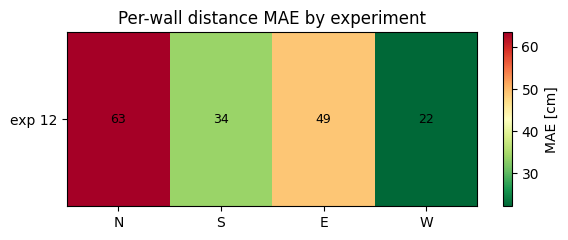

In [12]:
# Per-wall MAE — experiments × {N,S,E,W}
wall_mat = exp_tbl.loc[exps, [f"mae_{w}_cm" for w in WALL_LABELS]].astype(float)

fig, ax = plt.subplots(figsize=(6, 0.5 * len(wall_mat) + 2))
im = ax.imshow(wall_mat.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(4), WALL_LABELS)
ax.set_yticks(range(len(wall_mat)), [f"exp {e}" for e in wall_mat.index])
for i in range(wall_mat.shape[0]):
    for j in range(wall_mat.shape[1]):
        ax.text(j, i, f"{wall_mat.values[i, j]:.0f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="MAE [cm]")
ax.set_title("Per-wall distance MAE by experiment")
plt.tight_layout(); plt.show()

### Ranking chart

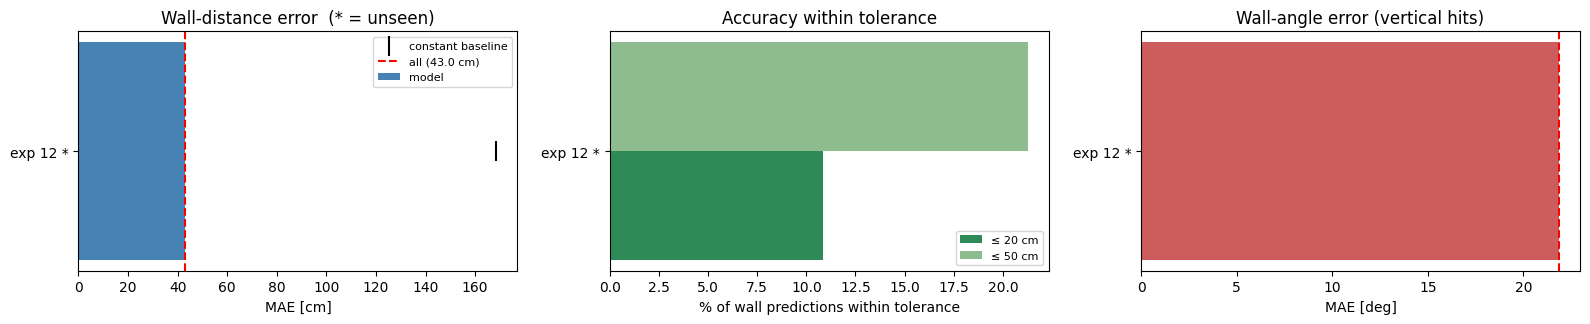

In [13]:
plot_tbl = exp_tbl.drop(index="ALL").sort_values("mae_dist_cm")
labels   = [f"exp {e}" + (" *" if IS_UNSEEN[e] else "") for e in plot_tbl.index]
fig, axes = plt.subplots(1, 3, figsize=(16, 0.35 * len(plot_tbl) + 3))

ax = axes[0]
ax.barh(labels, plot_tbl["mae_dist_cm"], color="steelblue", label="model")
if "baseline_cm" in plot_tbl:
    ax.scatter(plot_tbl["baseline_cm"], labels, marker="|", s=200, color="k",
               label="constant baseline", zorder=5)
ax.axvline(exp_tbl.loc["ALL", "mae_dist_cm"], color="red", ls="--",
           label=f"all ({exp_tbl.loc['ALL','mae_dist_cm']:.1f} cm)")
ax.set_xlabel("MAE [cm]"); ax.set_title("Wall-distance error  (* = unseen)")
ax.legend(fontsize=8)

ax = axes[1]
w = 0.38
ypos = np.arange(len(plot_tbl))
ax.barh(ypos - w/2, plot_tbl["acc<=20cm"] * 100, height=w, label="≤ 20 cm", color="seagreen")
ax.barh(ypos + w/2, plot_tbl["acc<=50cm"] * 100, height=w, label="≤ 50 cm", color="darkseagreen")
ax.set_yticks(ypos, labels)
ax.set_xlabel("% of wall predictions within tolerance"); ax.set_title("Accuracy within tolerance")
ax.legend(fontsize=8)

ax = axes[2]
ax.barh(labels, plot_tbl["mae_angle_vert_deg"], color="indianred")
ax.axvline(exp_tbl.loc["ALL", "mae_angle_vert_deg"], color="red", ls="--")
ax.set_xlabel("MAE [deg]"); ax.set_title("Wall-angle error (vertical hits)")
plt.tight_layout(); plt.show()

### Prediction vs ground truth, per experiment

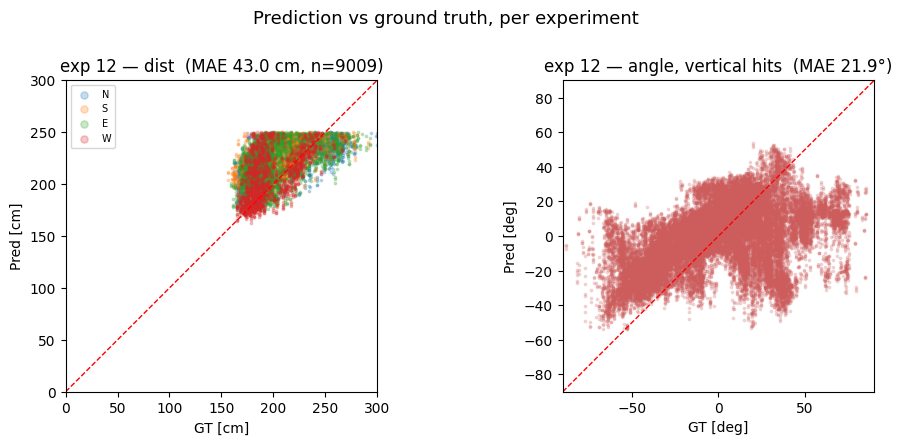

In [21]:
fig, axes = plt.subplots(len(exps), 2, figsize=(10, 4.4 * len(exps)), squeeze=False)
lim_d = (0, PLOT_MAX)
vert  = _vert(meta_val)
for ri, e in enumerate(exps):
    sel = col == e
    ax = axes[ri][0]
    for i, wl in enumerate(WALL_LABELS):
        ax.scatter(true_d[sel, i], np.clip(pred_d[sel, i], *lim_d), s=3, alpha=0.25, label=wl)
    ax.plot(lim_d, lim_d, "r--", lw=1)
    ax.set_xlim([0,300]); ax.set_ylim([0,300]); ax.set_aspect("equal")
    ax.set_xlabel("GT [cm]"); ax.set_ylabel("Pred [cm]")
    ax.set_title(f"exp {e} — dist  (MAE {exp_tbl.loc[e,'mae_dist_cm']:.1f} cm, "
                 f"n={int(exp_tbl.loc[e,'n'])})")
    ax.legend(fontsize=7, markerscale=3)

    ax = axes[ri][1]
    v = vert[sel]
    ax.scatter(true_a[sel][v], pred_a[sel][v], s=3, alpha=0.2, color="indianred")
    ax.plot(ANGLE_LIM, ANGLE_LIM, "r--", lw=1)
    ax.set_xlim(ANGLE_LIM); ax.set_ylim(ANGLE_LIM); ax.set_aspect("equal")
    ax.set_xlabel("GT [deg]"); ax.set_ylabel("Pred [deg]")
    ax.set_title(f"exp {e} — angle, vertical hits  "
                 f"(MAE {exp_tbl.loc[e,'mae_angle_vert_deg']:.1f}°)")
plt.suptitle("Prediction vs ground truth, per experiment", y=1.001, fontsize=13)
plt.tight_layout(); plt.show()

### Error distributions

/tmp/ipykernel_4154721/3710171462.py:28: RuntimeWarning: Mean of empty slice
  means = [np.nanmean(err[bidx == b]) if (bidx == b).sum() >= 20 else np.nan


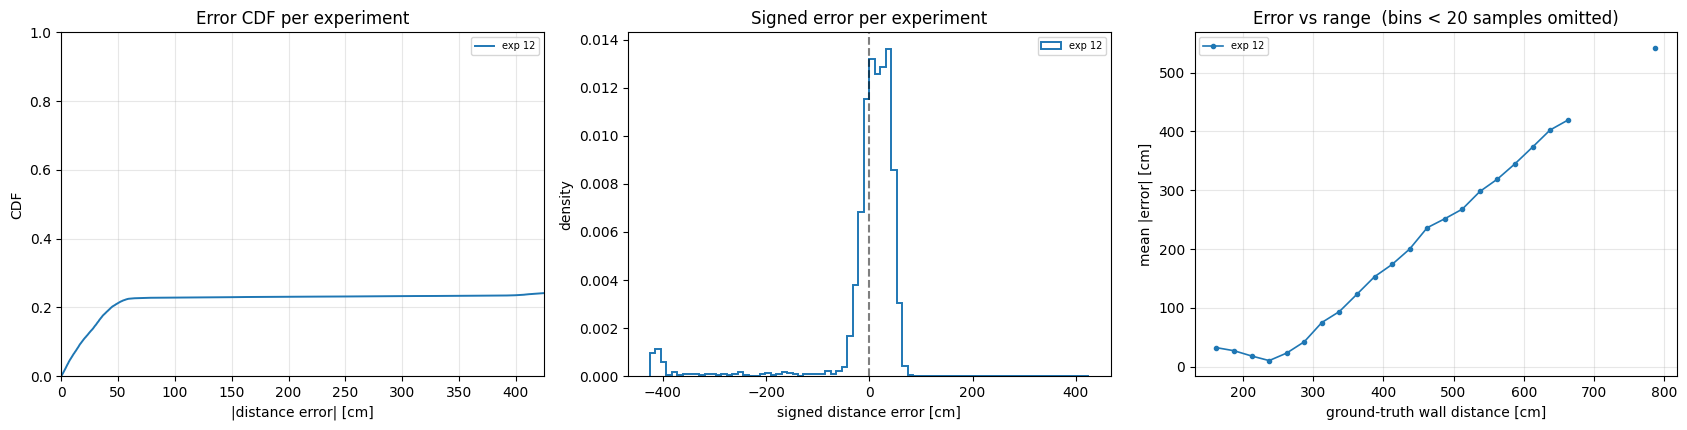

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

ax = axes[0]
for e in exps:
    err = np.sort(np.abs(pred_d[col == e] - true_d[col == e]).ravel())
    ax.plot(err, np.arange(1, len(err) + 1) / len(err), lw=1.4, label=f"exp {e}")
ax.set_xlim(0, 0.5 * PLOT_MAX); ax.set_ylim(0, 1)
ax.set_xlabel("|distance error| [cm]"); ax.set_ylabel("CDF")
ax.set_title("Error CDF per experiment"); ax.grid(alpha=0.3); ax.legend(fontsize=7)

ax = axes[1]
for e in exps:
    ax.hist((pred_d[col == e] - true_d[col == e]).ravel(), bins=80,
            range=(-0.5 * PLOT_MAX, 0.5 * PLOT_MAX), density=True,
            histtype="step", lw=1.4, label=f"exp {e}")
ax.axvline(0, color="k", ls="--", alpha=0.5)
ax.set_xlabel("signed distance error [cm]"); ax.set_ylabel("density")
ax.set_title("Signed error per experiment"); ax.legend(fontsize=7)

# Error vs ground-truth distance — does accuracy degrade with range?
ax = axes[2]
BIN_EDGES = np.arange(0, PLOT_MAX + 1, 25)
centers   = 0.5 * (BIN_EDGES[:-1] + BIN_EDGES[1:])
for e in exps:
    gt   = true_d[col == e].ravel()
    err  = np.abs(pred_d[col == e] - true_d[col == e]).ravel()
    bidx = np.digitize(gt, BIN_EDGES) - 1
    means = [np.nanmean(err[bidx == b]) if (bidx == b).sum() >= 20 else np.nan
             for b in range(len(centers))]
    ax.plot(centers, means, marker="o", ms=3, lw=1.2, label=f"exp {e}")
ax.set_xlabel("ground-truth wall distance [cm]"); ax.set_ylabel("mean |error| [cm]")
ax.set_title("Error vs range  (bins < 20 samples omitted)")
ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Train-split accuracy, per experiment

For an experiment on both sides, the train↔val gap is the overfitting check. With
`--val_experiments` the sides are disjoint, so the train experiments serve as the
in-distribution reference. Set `EVAL_TRAIN_SPLIT = False` to skip.

In [16]:
if EVAL_TRAIN_SPLIT:
    pred_d_tr, pred_a_tr = predict(X_train_eval)
    train_tbl = per_exp_table(pred_d_tr, true_d_tr, pred_a_tr, true_a_tr,
                              meta_train, order=train_sel)
    display(train_tbl[[c for c in _cols if c != "unseen"]].style.format(
        {k: v for k, v in _fmt.items() if k != "unseen"}
    ).set_caption("Train-split accuracy per experiment"))

    both = [e for e in exps if e in train_tbl.index]
    if both:
        gap = pd.DataFrame({
            "n_train":      train_tbl.loc[both, "n"],
            "n_val":        exp_tbl.loc[both, "n"],
            "mae_train_cm": train_tbl.loc[both, "mae_dist_cm"],
            "mae_val_cm":   exp_tbl.loc[both, "mae_dist_cm"],
        }).astype(float)
        gap["gap_cm"] = gap["mae_val_cm"] - gap["mae_train_cm"]
        gap["gap_%"]  = 100 * (gap["mae_val_cm"] / gap["mae_train_cm"] - 1)
        display(gap.style.format({"n_train": "{:.0f}", "n_val": "{:.0f}",
                                  "mae_train_cm": "{:.2f}", "mae_val_cm": "{:.2f}",
                                  "gap_cm": "{:+.2f}", "gap_%": "{:+.1f}%"})
                .background_gradient(subset=["gap_cm"], cmap="RdYlGn_r"))
    else:
        gap = None
        print("No experiment appears in both splits, so there's no per-experiment gap to report.")
else:
    train_tbl = gap = None
    print("skipped")

,n,mae_dist_cm,baseline_cm,gain_cm,medae_dist_cm,p90_dist_cm,rmse_dist_cm,bias_dist_cm,acc<=10cm,acc<=20cm,acc<=50cm,%oor,gt_dist_cm,mae_angle_deg,mae_angle_vert_deg,p90_angle_deg
1,198,186.45,233.89,+47.44,141.41,403.78,228.59,-50.81,0.4%,0.5%,11.1%,0.00,323.34,31.24,31.24,53.54
2,192,229.26,231.56,+2.30,193.20,413.56,267.05,-68.25,1.7%,2.2%,6.4%,0.00,345.66,24.71,24.74,65.55
3,195,178.08,209.78,+31.70,119.22,391.13,218.78,-73.46,0.9%,2.4%,8.1%,0.00,348.81,20.55,20.63,55.89
4,198,194.57,199.52,+4.95,174.62,363.37,236.97,-83.36,3.0%,7.6%,21.8%,0.00,359.72,34.12,34.12,68.87
5,198,163.58,185.98,+22.40,125.07,329.75,207.05,-82.81,6.3%,10.7%,23.9%,0.00,360.87,27.24,27.32,51.50
6,165,184.01,168.18,-15.82,179.72,317.84,211.38,-66.97,0.2%,1.4%,8.5%,0.00,340.05,28.16,30.60,71.22
7,192,178.03,177.69,-0.34,165.58,323.22,206.87,-92.30,0.3%,1.8%,9.8%,0.00,371.27,32.46,32.79,51.25
8,198,160.91,118.12,-42.78,141.96,317.41,188.89,-123.59,1.6%,3.8%,12.8%,0.00,392.91,33.19,33.60,57.17
9,198,131.62,104.49,-27.13,97.55,297.65,170.06,-126.27,6.7%,12.6%,28.9%,0.00,403.60,29.88,29.88,57.16
10,9009,120.32,109.08,-11.24,76.19,290.62,162.93,-117.17,11.3%,21.9%,40.7%,0.00,402.79,16.82,16.86,40.66


No experiment appears in both splits, so there's no per-experiment gap to report.


## Wall geometry — top view, per experiment

`visualize_walls3D` (T2TSionnaSim/MLNotebooks) draws a 10 cm wall patch at every
N/S/E/W hit, oriented by the wall angle, so the room outline emerges from the
val sub-clusters. Two figures per experiment: prediction, then ground truth.
The pose is clamped to the ground plane, matching the horizontal rays
`cluster_features.py` casts. Set `VIZ_EXPERIMENTS` / `VIZ_LIMIT` in the config cell.


  exp 12   400 of 9009 val samples   MAE 43.0 cm   [UNSEEN]
[exp 12] predictions — top view:


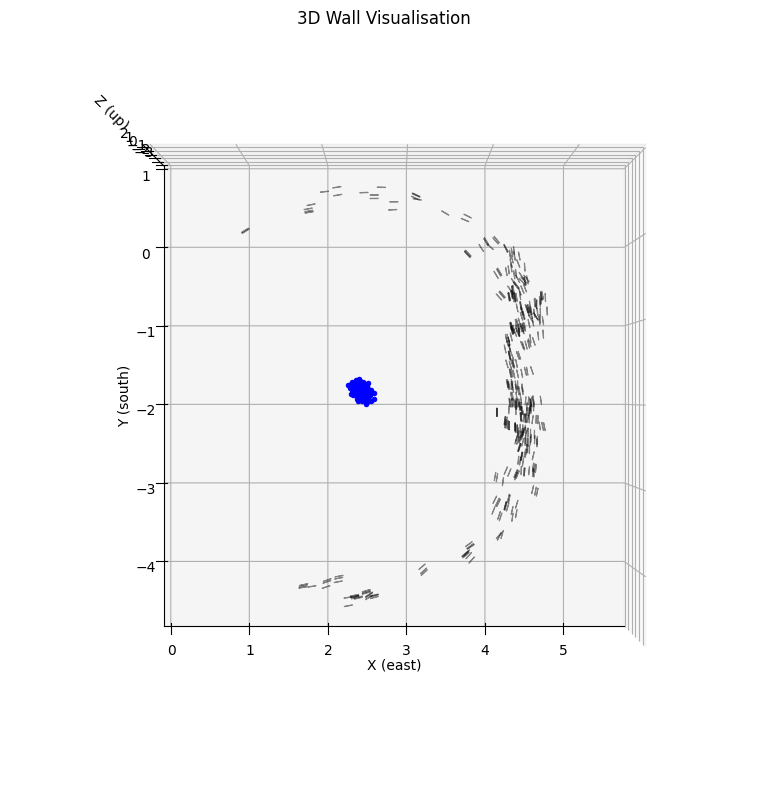

[exp 12] ground truth — top view:


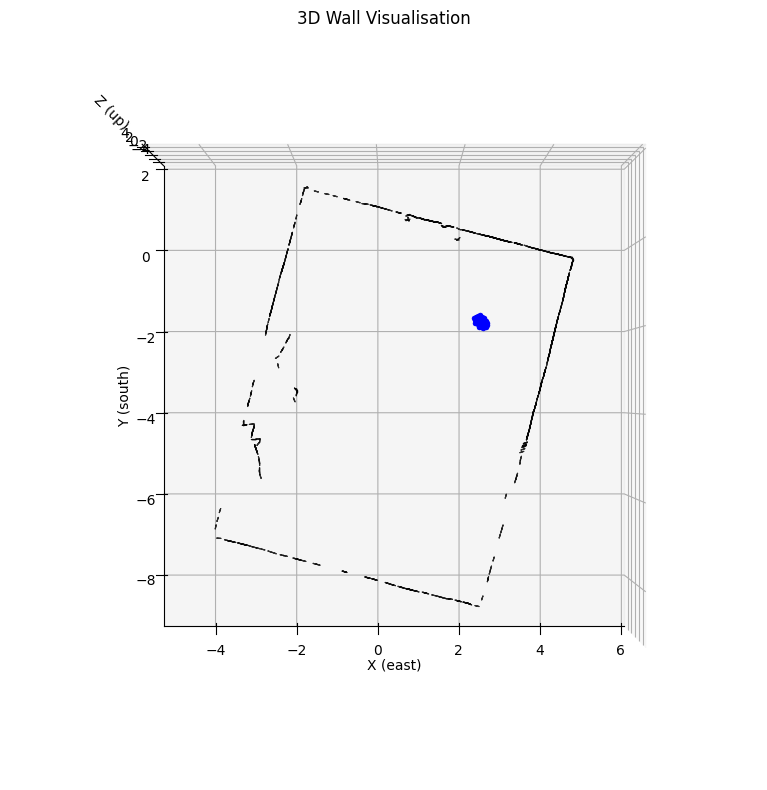

In [17]:
_viz_dir = os.path.join(_tc.T2T_ROOT, "MLNotebooks")
if _viz_dir not in sys.path:
    sys.path.insert(0, _viz_dir)
try:
    import vizualizeWalls
    importlib.reload(vizualizeWalls)
    from vizualizeWalls import visualize_walls3D
except ImportError as e:
    visualize_walls3D = None
    print("vizualizeWalls not importable:", e)

viz_exps = exps if VIZ_EXPERIMENTS is None else [e for e in VIZ_EXPERIMENTS if e in exps]

if visualize_walls3D is None:
    print("Skipped — vizualizeWalls missing.")
else:
    # Out-of-range predictions become NaN (skipped by the plot) so one blown-up
    # sample cannot stretch the axes and hide the rest of the room.
    pred_d_viz = np.where((pred_d < DIST_LIM[0]) | (pred_d > DIST_LIM[1]), np.nan, pred_d)

    for e in viz_exps:
        sel = np.flatnonzero(col == e)[:VIZ_LIMIT]
        print("\n" + "=" * 78)
        print(f"  exp {e}   {len(sel)} of {int(exp_tbl.loc[e, 'n'])} val samples   "
              f"MAE {exp_tbl.loc[e, 'mae_dist_cm']:.1f} cm"
              + ("   [UNSEEN]" if IS_UNSEEN[e] else ""))
        print("=" * 78)

        # Blue dots = cluster centroids (ray origins)
        print(f"[exp {e}] predictions — top view:")
        visualize_walls3D(gt_centers[sel], gt_poses[sel],
                          pred_d_viz[sel] / 100.0, pred_a[sel],
                          show_pose_arrow=False, show_centers=True,
                          clamp_to_ground_plane=True, elev=90, azim=-90)
        print(f"[exp {e}] ground truth — top view:")
        visualize_walls3D(gt_centers[sel], gt_poses[sel],
                          true_d[sel] / 100.0, true_a[sel],
                          show_pose_arrow=False, show_centers=True,
                          clamp_to_ground_plane=True, elev=90, azim=-90)

## Export

In [18]:
out_csv = os.path.join(SAVED_DIR, run_cfg["run_stem"] + "_perexp_eval.csv")
export = exp_tbl.copy()
if gap is not None:
    export = export.join(gap[["mae_train_cm", "gap_cm", "gap_%"]], how="left")
export.index.name = "experiment"
export.to_csv(out_csv)
print(f"Per-experiment metrics → {out_csv}")

# Per-sample val predictions, keyed by the same sample_idx / csv_rows as _split.csv
pred_csv = os.path.join(SAVED_DIR, run_cfg["run_stem"] + "_val_predictions.csv")
_p = meta_val[["sample_idx"] + SUB_KEYS + ["run", "csv_rows"]].copy()
for j, wl in enumerate(WALL_LABELS):
    _p[f"gt_dist_{wl}_cm"], _p[f"pred_dist_{wl}_cm"] = true_d[:, j], pred_d[:, j]
    _p[f"gt_angle_{wl}_deg"], _p[f"pred_angle_{wl}_deg"] = true_a[:, j], pred_a[:, j]
_p.to_csv(pred_csv, index=False)
print(f"Val predictions        → {pred_csv}")

Per-experiment metrics → /home/manaj/RFImaging/multitag_ml_training/Saved/ETF_realistic_45slots_attn_d128_l6_ep300_s42_1014155745_ft_frz5_valexp12_ep20_s42_1014221153_perexp_eval.csv
Val predictions        → /home/manaj/RFImaging/multitag_ml_training/Saved/ETF_realistic_45slots_attn_d128_l6_ep300_s42_1014155745_ft_frz5_valexp12_ep20_s42_1014221153_val_predictions.csv
